In [ ]:
import sys
import os

sys.path.append('..')

import warnings

import pandas as pd
from matplotlib import pyplot as plt

from BPASS_Grid_Fit import ConfigureGrid as cfg
from BPASS_Grid_Fit import BPASSGrid as bpg

tqdm is not available - no feedback on execution


In [2]:
# define where the grid hdf5 file is located
grid_file = '../BPASS_Grid/grid_07_2025.hdf5'

In [ ]:
# specify the full grid parameters that you want to generate a fits file for
# full parameter range is given in ../BPASS_Grid/README.txt

# full grid params

# metallicity
Z = [1e-4, 2e-4, 5e-4, 1e-3, 2e-3, 4e-3, 6e-3, 8e-3, 1e-2, 1.4e-2, 1.7e-2, 2e-2, 3e-2, 4e-2]
# ionization parameter (given as log10(U))
U = [-4.0, -3.5, -3.0, -2.5, -2.0, -1.5, -1.0]
# dust to metal ratio
xsi = [0.3]
# gas density (given as log10(n_H/cm^-3))        
n_H = [3.0]
# C/O ratio
CO = [0.044]
# define the ages to integrate over in the fits file (in years)
age = [10**(6+0.1*(x-2)) for x in range(2, 23)]
ages = [f'{y:.2e}' for y in age]

# note the column definitions for the hdf5 file datasets

# grid_07_2025.hdf5 contains the following columns for each model:
columns=['Z', 'ha', 'hb', 'o1_6300', 'o2_3727', 'o3_1666', 'o3_4959', 'o3_5007','s2_6716_6731', 'n2_6548', 'n2_6584', 'n5_1243', 'he1_3965', 'he1_4471', 'he1_5876', 'he1_6678', 'he2_1640', 'he2_4686', 'c3_1909', 'c4_1551', 'si3_1892', 'he1_1083', 'n_H']
# grid_07_2025_solar.hdf5 contains the following columns for each model:
#columns=['Z', 'ha', 'hb', 'o1_6300', 'o2_3727', 'o3_1666', 'o3_4959', 'o3_5007','s2_6716_6731', 'n2_6548', 'n2_6584', 'n5_1243', 'he1_3965', 'he1_4471', 'he1_5876', 'he1_6678', 'he2_1640', 'he2_4686', 'c3_1909', 'c4_1551', 'si3_1892', 'he1_1083', 'n_H', 'hg', 'hd', 'o3_4363', 'ne3_3868', 'ar4_4711']

params = {
            'Z': Z,
            'U': U,
            'xsi': xsi,
            'nH': n_H,
            'CO': CO,
            'age': age
         }


In [4]:
# define a version number for the fits file to be generated
v = 1

In [16]:
# define the lines to be included in the fits file
lines = ['HB', 'OIII4959', 'OIII5007', 'OII3727', 'HA', 'SII6716', 'SII6731', 'NII6584', 'NII6548']

In [17]:
if not os.path.exists(f'BPASS_grid_v{v}.fits'):
    config_grid = cfg.ConfigureGrid(
                                    grid = grid_file,
                                    params= params,
                                    columns=columns,
                                    )
        
    with warnings.catch_warnings(action='ignore', category=FutureWarning):
        
        warnings.simplefilter('ignore', pd.errors.ChainedAssignmentError)
        warnings.simplefilter('ignore', pd.errors.SettingWithCopyWarning)
        
        config_grid.load_grid()
        config_grid.grid_setup()
        config_grid.save_grid(filename=f'BPASS_grid_v{v}.fits')
        
grid = bpg.Grid(
                name=f'BPASS_grid_v{v}',
                pars=['LOGZ', 'LOGU'],
                lines=lines,
                fix=None,
                path=f'./BPASS_grid_v{v}.fits',
                recalculate=False
                )

Adding a logarithmic quantity Log_HB
Adding a logarithmic quantity Log_OIII4959
Adding a logarithmic quantity Log_OIII5007
Adding a logarithmic quantity Log_OII3727
Adding a logarithmic quantity Log_HA
Adding a logarithmic quantity Log_SII6716
Adding a logarithmic quantity Log_SII6731
Adding a logarithmic quantity Log_NII6584
Adding a logarithmic quantity Log_NII6548


Creating unique parameter mapping - this can take a little while
In create_parameter_mapping!


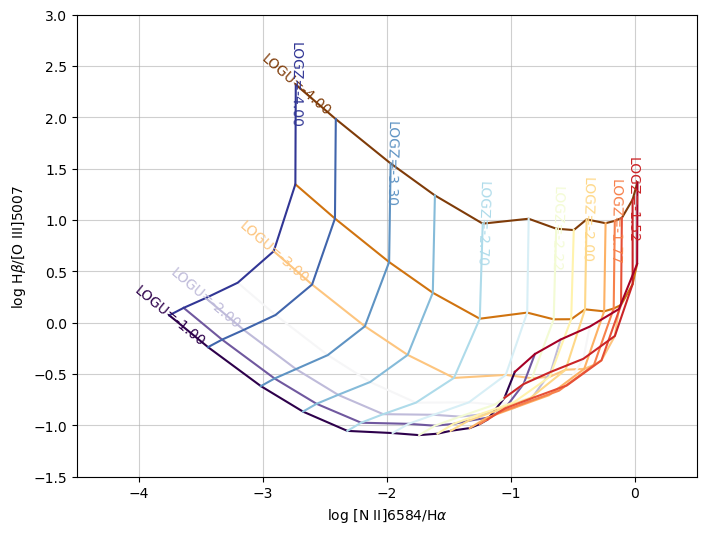

In [18]:
diagnostic = grid.get_diagnostic_diagram(    'NII6584', 'HA', 'HB', 'OIII5007', parameter_name1='LOGZ', parameter_name2='LOGU', parameter_range1=[-4, -1], parameter_range2=[-4, -1])

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111)

diagnostic.show(ax=ax, cmap1='RdYlBu_r', cmap2='PuOr')

ax.set_xlim(-4.5, 0.5)
ax.set_ylim(-1.5, 3.0)

ax.grid(alpha=0.6, zorder=0)
